# Barnacle counter

Can model proposals help a scientist count barnacles inside a field frame? This
notebook follows the data, prototype, and evaluation behind a small review tool.
The cells read saved measurements and figures; training is a separate command.

The workflow is: select the frame, generate tiled proposals, correct them, then
save a provisional count. The experiment focuses on the proposal step. Whether
assisted counting is faster than manual counting remains an open question.

## 1. What to try

An instance mask gives a scientist something to inspect and correct. With two
annotated photographs, a pretrained Mask R-CNN is one possible starting point.
Compare it with bright connected components and a simple density-based count.
Selecting the frame manually keeps this experiment focused; a crop derived from
annotation masks would not be available on a new field photograph.

Evaluate both the total count and the individual masks. Count error alone can
hide equal numbers of misses and extras. Use one-to-one matching at mask IoU 0.5,
with a fixed model score cutoff of 0.5. The other cutoffs are sensitivity checks.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from src.dataset import BarnacleDataset
from src.preprocess import preprocess_raw

root = Path.cwd()
if not (root / "results/report.json").exists():
    raise RuntimeError("Start Jupyter from the repository root.")
report = json.loads((root / "results/report.json").read_text())
audit = json.loads((root / "results/annotation_audit.json").read_text())
print("Recorded environment:", report["environment"])
print("Original image-level split: train 1 → evaluate 2; train 2 → evaluate 1")

Recorded environment: {'torch': '2.11.0', 'torchvision': '0.26.0', 'numpy': '2.4.4', 'opencv-python': '4.13.0.92', 'scipy': '1.17.1', 'matplotlib': '3.10.9'}
Original image-level split: train 1 → evaluate 2; train 2 → evaluate 1


## 2. Check the data and recovered labels

The original photographs and masks share coordinates. The supplied
`masked_img*.png` files are cropped overlays, so they cannot replace those inputs.
Blue outlines are filled separately, and an instance counts when its centroid is
inside or on the selected frame.

A 3×3 closing step in the earlier pipeline joined nearby labels. Without it,
image 1 yields 1,718 contours rather than 1,500; 1,702 fall within the frame.
Inspect the conversion below before treating the recovered masks as references.
They still contain the omissions and ambiguities of the supplied annotations.

img1.png: 1702 references in frame; 16 excluded; 0.89 MB compact masks vs 13.73 GB full masks
img2.png: 389 references in frame; 8 excluded; 0.65 MB compact masks vs 3.17 GB full masks


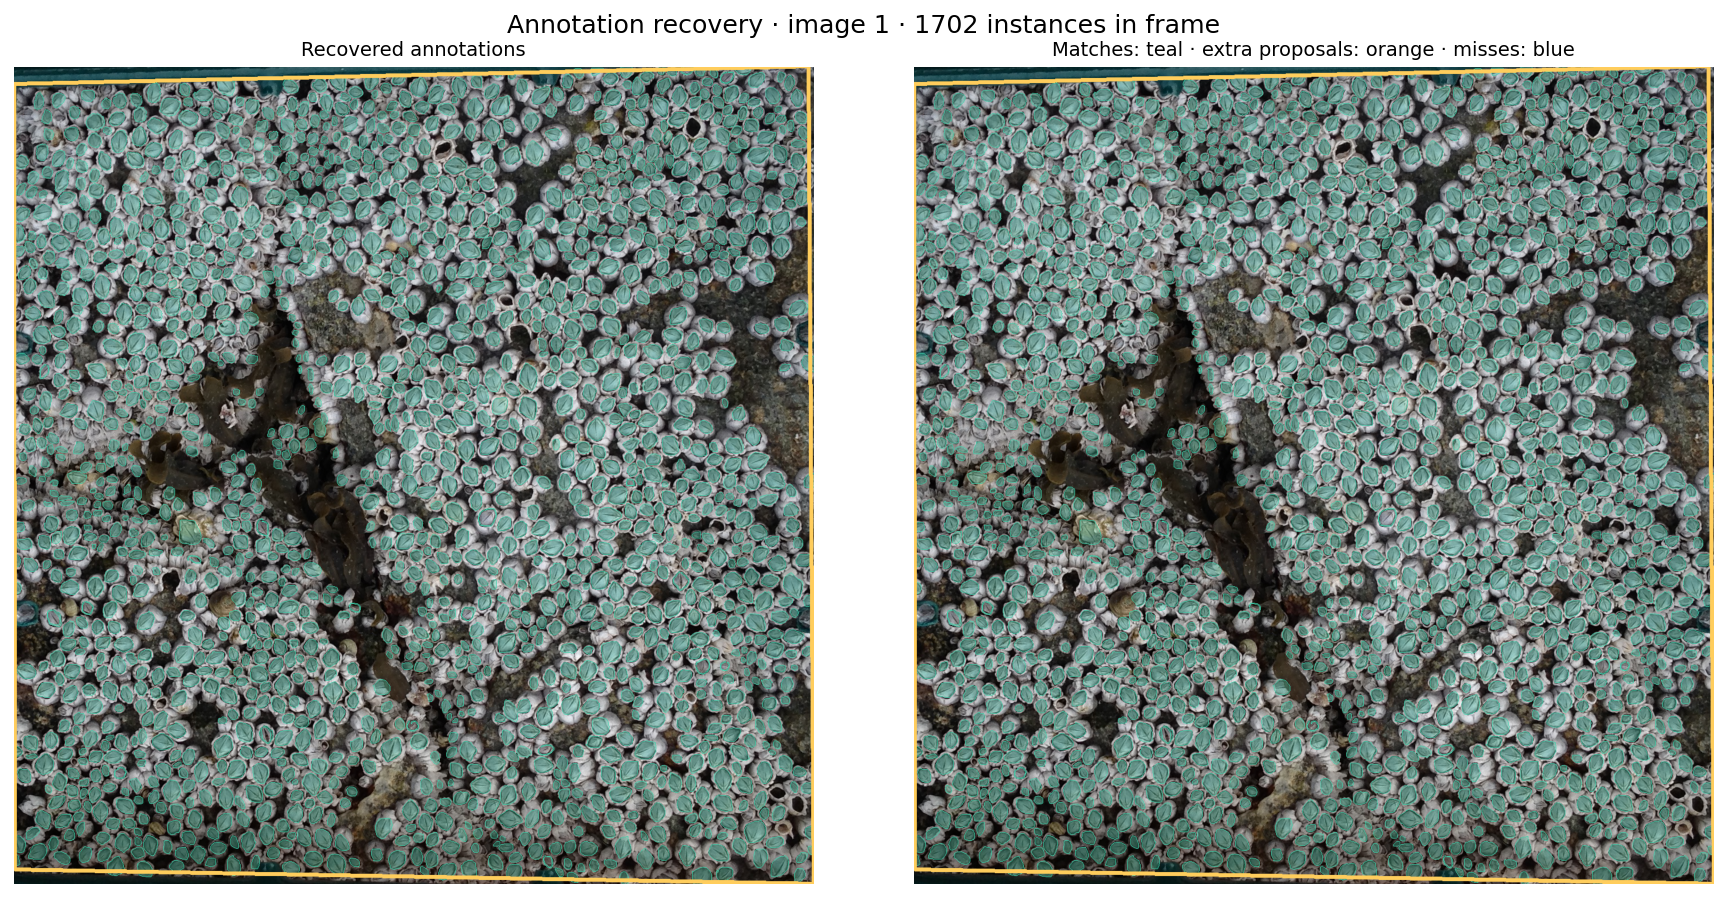

In [2]:
for row in audit:
    print(f'{row["image"]}: {row["reference_in_region"]} references in frame; '
          f'{row["excluded_outside_region"]} excluded; '
          f'{row["compact_mask_bytes"] / 1e6:.2f} MB compact masks '
          f'vs {row["full_mask_bytes_if_materialized"] / 1e9:.2f} GB full masks')
display(Image(filename="results/figures/annotation_audit_1.png", width=1000))

## 3. Look at one training tile

Separate photographs before making overlapping patches. The dataset loads each
photo once, stores masks in tight boxes, and builds a target only for the requested
tile. Edge-anchored windows cover the final strips. Empty tiles and visible object
fragments stay in training.

Both training and inference use 512-pixel tiles and black out the region exterior.
The frozen COCO backbone supplies visual features; new heads learn the barnacle
class. Each fold starts independently from COCO weights.

Training image 1 only: 16 patches
Input: (3, 512, 512) torch.float32 range: 0.0 0.9882352948188782
Target masks: (232, 512, 512) torch.uint8
Target boxes: (232, 4) label: [1]


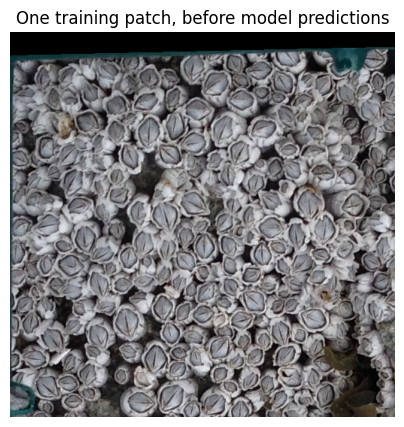

In [3]:
dataset = BarnacleDataset(["data/img1.png"], ["data/mask1.png"],
                           preprocess_fn=preprocess_raw, patch_size=512, patch_stride=384)
image, target = dataset[0]
print("Training image 1 only:", len(dataset), "patches")
print("Input:", tuple(image.shape), image.dtype, "range:", float(image.min()), float(image.max()))
print("Target masks:", tuple(target["masks"].shape), target["masks"].dtype)
print("Target boxes:", tuple(target["boxes"].shape), "label:", target["labels"].unique().tolist())
plt.figure(figsize=(5, 5))
plt.imshow(image.permute(1, 2, 0))
plt.title("One training patch, before model predictions")
plt.axis("off")
plt.show()

## 4. Train and evaluate across photographs

The recorded run uses seed 42, five epochs, AdamW, raw RGB, and two CPU threads.
Train on image 1 and evaluate image 2, then reverse. Checkpoint metadata records
the configuration, losses, package versions, and source hashes.

To repeat the model experiment, run from the repository root:

```bash
python -m src.experiment --epochs 5
```

A separate model trains on both images for the unlabeled demonstration. It is
not used in either held-out evaluation. Falling loss below is evidence of
optimization; the table answers the separate question of prediction quality.

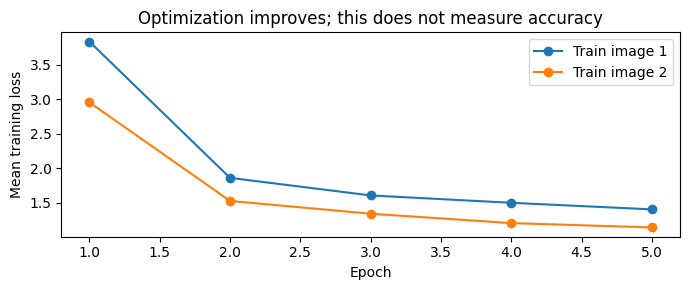

| Train → evaluation | Ref / predicted | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| 1 → 2 | 389 / 756 | 31.1% | 60.4% | 0.410 |
| 2 → 1 | 1702 / 1027 | 84.6% | 51.1% | 0.637 |

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
for fold in report["folds"]:
    history = fold["training"]["history"]
    ax.plot([h["epoch"] for h in history], [h["total_loss"] for h in history],
            marker="o", label=f'Train image {fold["train_image"]}')
ax.set(xlabel="Epoch", ylabel="Mean training loss", title="Optimization improves; this does not measure accuracy")
ax.legend()
fig.tight_layout()
plt.show()

rows = [m for m in report["metrics"] if m["score_threshold"] == 0.5 and m["method"] == "mask_rcnn"]
lines = ["| Train → evaluation | Ref / predicted | Precision | Recall | F1 |", "| --- | ---: | ---: | ---: | ---: |"]
for m in rows:
    lines.append(f'| {m["train_image"]} → {m["test_image"]} | {m["reference_count"]} / {m["predicted_count"]} | '
                 f'{m["precision"]:.1%} | {m["recall"]:.1%} | {m["f1"]:.3f} |')
display(Markdown("\n".join(lines)))

## 5. Compare the simple baselines

On image 2, bright components have a smaller count error than Mask R-CNN
(155 versus 367), yet their F1 is only 0.003. They barely match the individual
annotations. That result shows how misses and extras can cancel in a total.

Transferring the training photograph's density also fails across the scenes.
These are fixed, simple comparisons; they do not rule out a better classical
vision method.

In [5]:
lines = ["| Method | Evaluation image | Absolute count error | F1 |", "| --- | ---: | ---: | ---: |"]
for m in report["metrics"]:
    if m["method"] == "mask_rcnn" and m["score_threshold"] != 0.5:
        continue
    f1 = f'{m["f1"]:.3f}' if m["f1"] is not None else "N/A (no localization)"
    lines.append(f'| {m["method"]} | {m["test_image"]} | {m["absolute_count_error"]} | {f1} |')
display(Markdown("\n".join(lines)))

| Method | Evaluation image | Absolute count error | F1 |
| --- | ---: | ---: | ---: |
| mask_rcnn | 2 | 367 | 0.410 |
| bright_components | 2 | 155 | 0.003 |
| constant_training_density | 2 | 1805 | N/A (no localization) |
| mask_rcnn | 1 | 675 | 0.637 |
| bright_components | 1 | 720 | 0.000 |
| constant_training_density | 1 | 1400 | N/A (no localization) |

## 6. Inspect the errors

Teal marks matched masks, orange extra proposals, and blue missed references.
The model trained on the dense photograph overcounts the darker photograph.
The reverse fold has better precision but misses many instances in the dense scene.

The figures help locate those failures. Incomplete labels, mask-shape disagreement
at the IoU cutoff, and tile seams also affect the interpretation. A scientist
would need to check and correct these proposals.

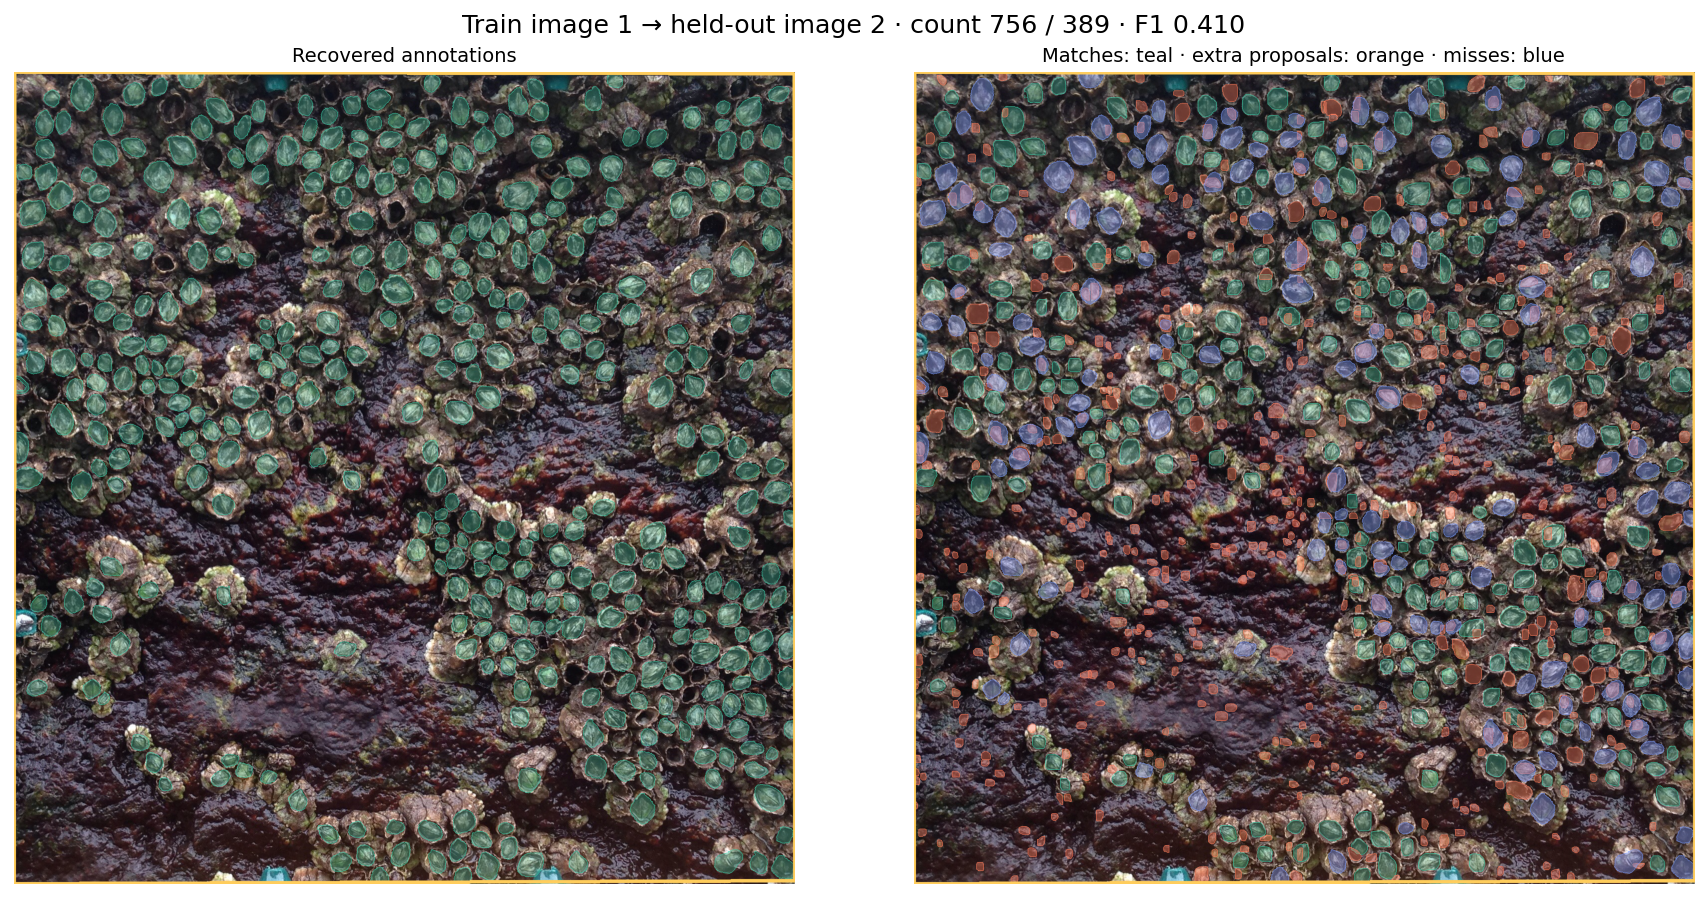

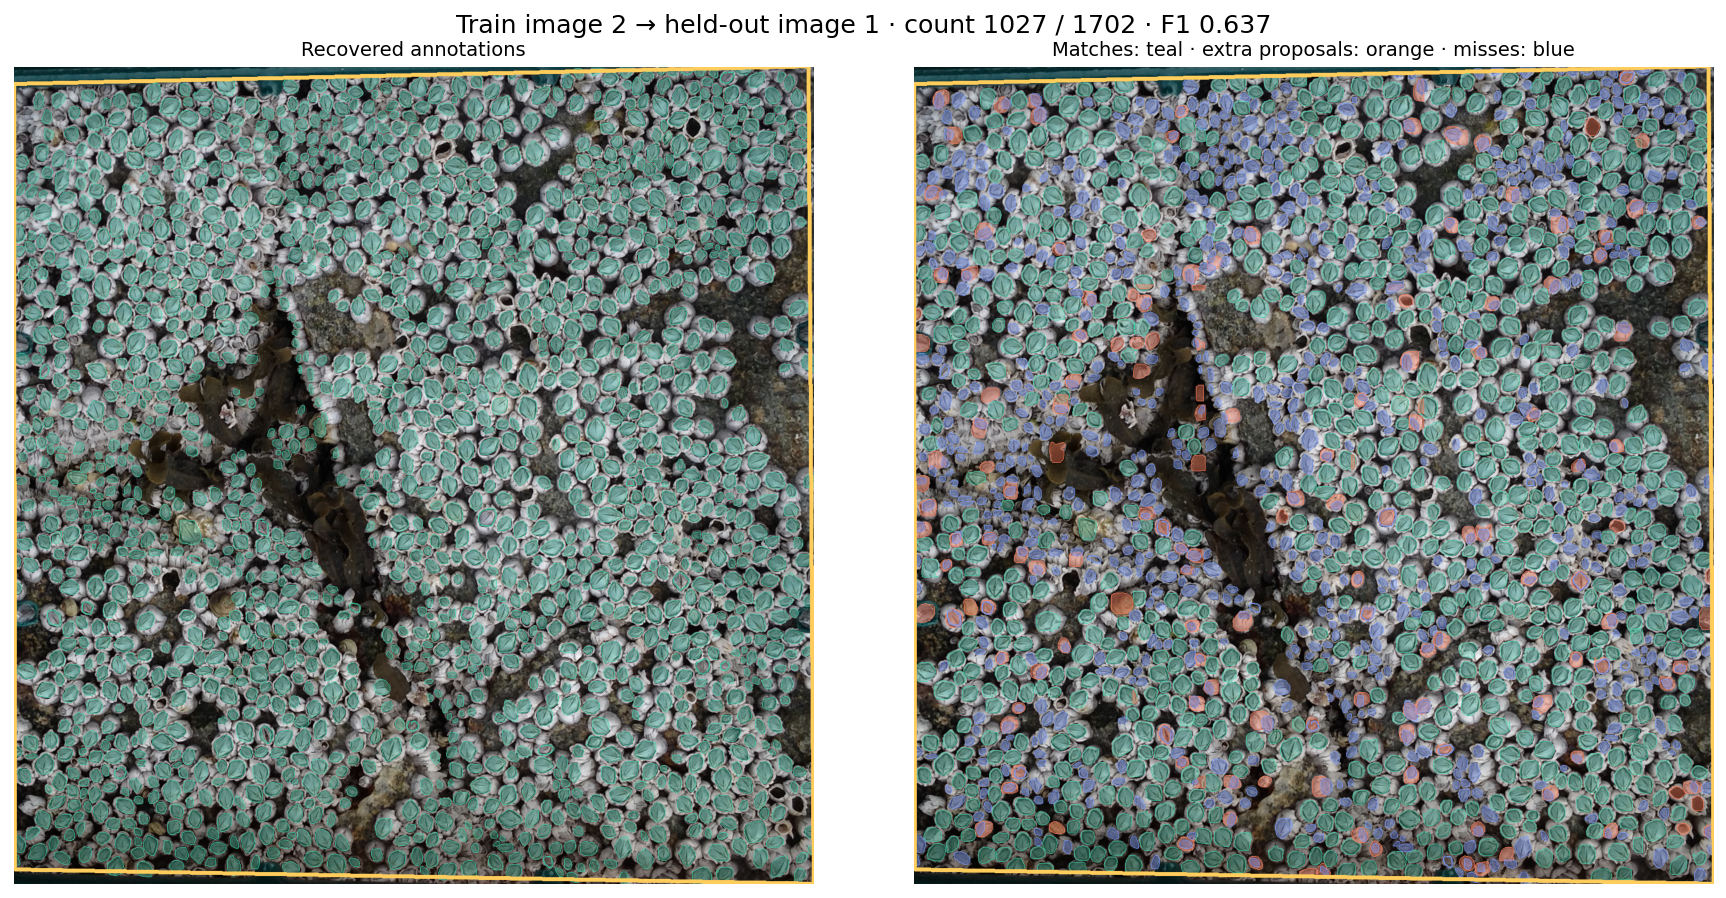

In [6]:
display(Image(filename="results/figures/heldout_2.png", width=1000))
display(Image(filename="results/figures/heldout_1.png", width=1000))

## 7. Change the score cutoff

Higher cutoffs usually trade recall for precision. There is no separate validation
set in this two-photograph experiment, so the values below are exploratory. The
primary results stay at 0.5. A model score is not a calibrated probability.

In [7]:
lines = ["| Evaluation image | Score | Predicted count | Precision | Recall |", "| --- | ---: | ---: | ---: | ---: |"]
for m in report["metrics"]:
    if m["method"] == "mask_rcnn":
        lines.append(f'| {m["test_image"]} | {m["score_threshold"]:.2f} | {m["predicted_count"]} | '
                     f'{m["precision"]:.1%} | {m["recall"]:.1%} |')
display(Markdown("\n".join(lines)))

| Evaluation image | Score | Predicted count | Precision | Recall |
| --- | ---: | ---: | ---: | ---: |
| 2 | 0.25 | 1402 | 19.8% | 71.5% |
| 2 | 0.50 | 756 | 31.1% | 60.4% |
| 2 | 0.75 | 252 | 49.6% | 32.1% |
| 1 | 0.25 | 1125 | 80.5% | 53.2% |
| 1 | 0.50 | 1027 | 84.6% | 51.1% |
| 1 | 0.75 | 820 | 90.1% | 43.4% |

## 8. Review the unlabeled photograph

The separate model trained on both labeled images produces 820 proposals at
score 0.5 on `unseen_img1.png`. There is no reference count for this photograph.

The browser tool displays saved model proposals. It supports tile navigation,
score filtering, removing extras, marking misses, undo, frame selection, and
downloads in original coordinates. Counts remain provisional: the interface
cannot establish that a scientist checked every instance.

```bash
python -m http.server 8000 --bind 127.0.0.1
# Open http://127.0.0.1:8000/demo/
```

See [the review instructions](docs/review_workflow.md) for new photographs and exports.

Official unseen photo: unseen_img1.png
Proposals at score 0.5: 820
Accuracy: None (no reference labels)
Tiled inference seconds: 11.56


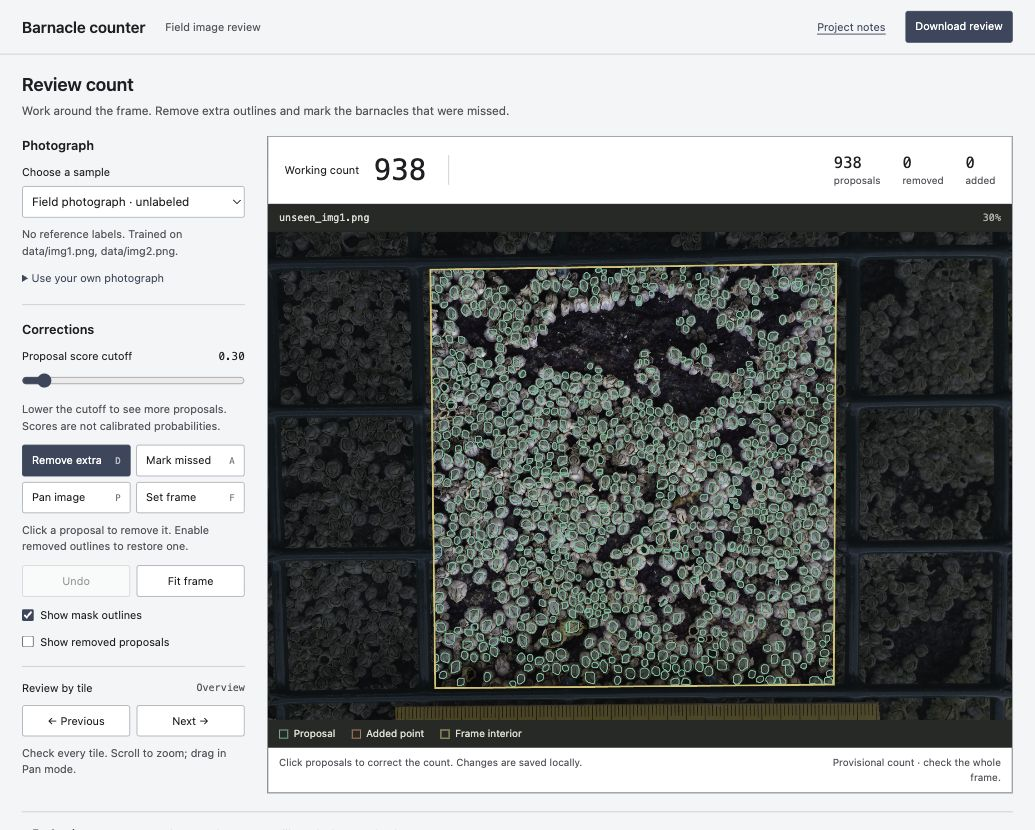

In [8]:
unseen = json.loads(Path("results/unseen_demo.json").read_text())
print("Official unseen photo:", unseen["image"])
print("Proposals at score 0.5:", unseen["proposals_at_0_5"])
print("Accuracy:", unseen["accuracy"], "(no reference labels)")
print("Tiled inference seconds:", round(unseen["inference"]["seconds"], 2))
display(Image(filename="results/figures/review_interface.jpg", width=1000))

## 9. What to do next

The proposal-and-correction approach is worth testing further. The model results
do not support automatic counts, and the interface has not been shown to save time.

Several details mattered more than expected from the initial model setup. Label
closing changed the reference count before training. Compact masks made the dense
photo practical to process. The baseline exposed the weakness of evaluating only
a total, while image-level evaluation exposed failures that training loss hid.

The next study should confirm counting conventions, audit annotations, and gather
independent photographs across lighting, density, and scale. Reserve validation
images before tuning. Compare manual and assisted counting on verified regions,
measuring both final error and task time.

Two directional results cannot establish generalization. Frame selection is
approximate, pixel density is not physical density, and duplicate suppression
can leave split instances or remove neighbors. Those are reasons to investigate
the pipeline and workflow before adding model complexity.

Codex assisted with the revision. The measurements come from local runs.
[README.md](README.md) contains reproduction instructions and references;
[the code walkthrough](docs/code_walkthrough.md) is the next reading step.